# R10 Gamma Beam Analysis — Source 1 vs Source 2 (clean geometry)

**源1**: x=30cm, 锥角 ±18°, 1e6 事件  
**源2**: x=200cm, iso ±0.1°（近似平行束）, 1e6 事件  

**能谱**: gammaON_merged.txt（1.0–8.0 MeV, 93 bins）  
**几何**: clean 版（`cevns_clean.xml`）——仅 LXe TPC（XenonDetector + XenonVeto1 + 内部结构），无 Air/容器/veto  
**注意**: 束流方向已修正（rot2=0,-1,0），命中率 ~72%（源1）/ ~93%（源2）  
**命名**: 原 source3（x=200cm 近平行束）已统一改名为 source2；旧 source2（4° 锥、方向错误）已废弃

**核心物理量（2026-08-01 新定义）**：
$$\theta = \angle(p_{in}, p_{out})$$
γ 在 **LXe TPC（volume==XenonDetector）内每一次 Compton 相互作用**的入射↔出射夹角。
- 不限定"首次"——TPC 内每次相互作用都算（单重 + 多重）
- $p_{in}$ 用该步 **PreStep 入射动量**（`gammaCompPrePx/Py/Pz`），不是 primaryPx
- 数据从 **ROOT 直接读取**（h5 的 gammaComp 无体积/无入射动量字段）

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.style as mplstyle
from pathlib import Path
from scipy.stats import gaussian_kde
from scipy import constants
import uproot
import awkward as ak
from collections import defaultdict

# 物理常量
M_E_C2 = 511.0          # keV (电子静止能量)
R_TPC = 82.5            # mm (TPC 内半径)
HALF_Z_TPC = 153.575 / 2  # mm (TPC 半高)
SRC1_POS = np.array([300.0, 0.0, -75.5])    # 源1位置 (mm)
SRC2_POS = np.array([2000.0, 0.0, -75.5])   # 源2位置 (mm)

## §1 加载数据

In [2]:
def load_data(h5_path):
    """Load HDF5 data, return dict with events, primaries, clusters arrays."""
    data = {}
    with h5py.File(h5_path, 'r') as f:
        print(f"Datasets: {list(f.keys())}")
        n_total = len(f['events'])
        print(f"Total events: {n_total:,}")
        data['events'] = f['events'][:]
        data['primaries'] = f['primaries'][:]
        data['clusters'] = f['clusters'][:]
    return data

# 数据路径 — 使用拼接能谱 gammaON_merged.txt (1.0-8.0 MeV) 重新模拟的结果
H5_S1 = Path("../result/gamma_source1_1e6_clean.h5")
H5_S2 = Path("../result/gamma_source2_1e6_clean.h5")

# 只接受当前 1e6 clean 数据；不要静默回退到已废弃的 1e8 路径
missing_h5 = [path for path in (H5_S1, H5_S2) if not path.exists()]
if missing_h5:
    missing_text = ', '.join(str(path) for path in missing_h5)
    raise FileNotFoundError(
        f"Missing current clean HDF5 file(s): {missing_text}. Run Sorting.py first."
    )

data_s1 = load_data(H5_S1)
data_s2 = load_data(H5_S2)

for label, d in [("Source 1", data_s1), ("Source 2", data_s2)]:
    e, c, p = d['events'], d['clusters'], d['primaries']
    print(f"\n=== {label} ===")
    print(f"  events: {len(e):,}  |  clusters: {len(c):,}  |  primaries: {len(p):,}")
    print(f"  nClusters/event: mean={e['nClusters'].mean():.2f}, max={e['nClusters'].max()}")
    print(f"  nHits/event:     mean={e['nHits'].mean():.2f}, max={e['nHits'].max()}")
    print(f"  zero-cluster:    {(e['nClusters']==0).sum()}")
    print(f"  sum_er:          mean={e['sum_er'].mean():.1f}, max={e['sum_er'].max():.1f} keV")
    print(f"  cluster energy:  mean={c['energy'].mean():.1f}, max={c['energy'].max():.1f} keV")
    print(f"  primaryEnergy:   mean={p['primaryEnergy'].mean():.1f}, range=[{p['primaryEnergy'].min():.0f},{p['primaryEnergy'].max():.0f}] keV")

Datasets: ['clusters', 'events', 'gammaComp', 'primaries']
Total events: 714,736
Datasets: ['clusters', 'events', 'gammaComp', 'primaries']
Total events: 930,959

=== Source 1 ===
  events: 714,736  |  clusters: 1,492,942  |  primaries: 714,736
  nClusters/event: mean=2.09, max=15
  nHits/event:     mean=70.76, max=7541
  zero-cluster:    58859
  sum_er:          mean=nan, max=nan keV
  cluster energy:  mean=458.7, max=7877.6 keV
  primaryEnergy:   mean=1605.3, range=[1014,121910076] keV

=== Source 2 ===
  events: 930,959  |  clusters: 2,088,532  |  primaries: 930,959
  nClusters/event: mean=2.24, max=15
  nHits/event:     mean=72.30, max=6397
  zero-cluster:    52852
  sum_er:          mean=nan, max=nan keV
  cluster energy:  mean=457.8, max=7597.3 keV
  primaryEnergy:   mean=1567.5, range=[1014,120046878] keV


## §2 初级能谱 (Primary Energy Spectrum)

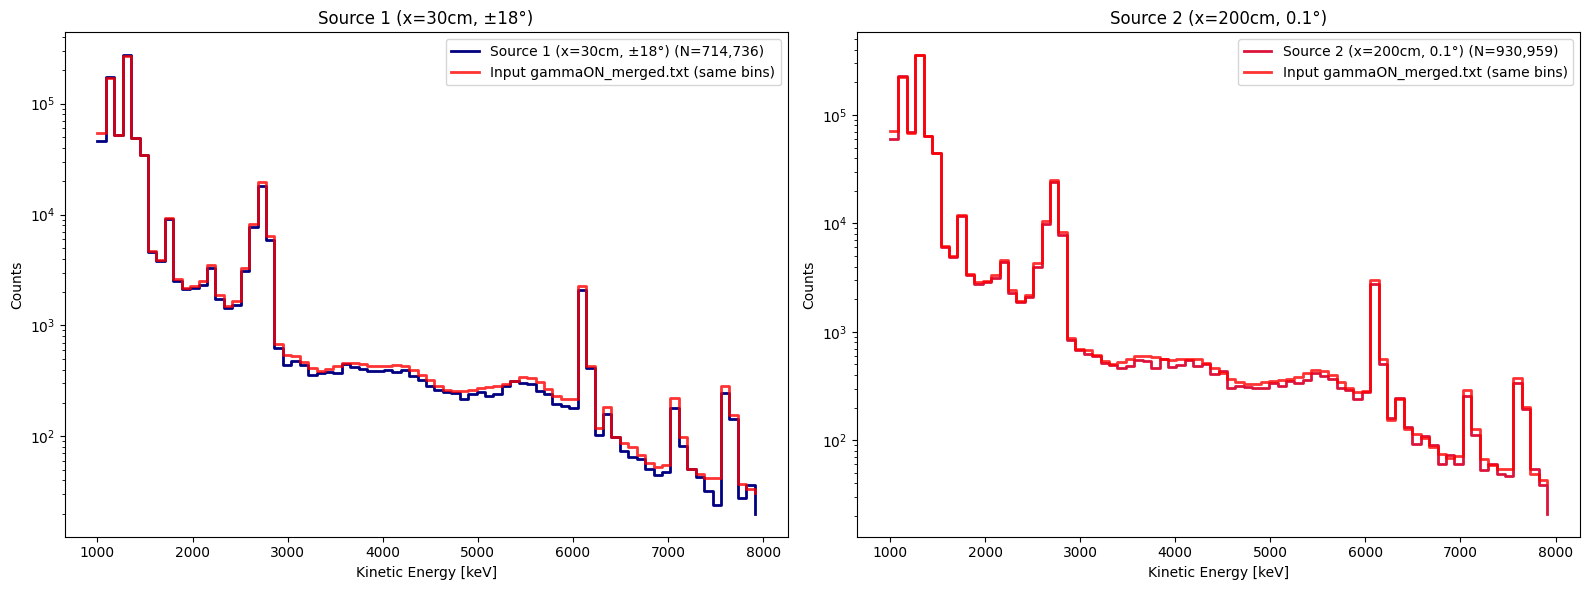

Source 1: primaryEnergy range=[1014, 121910076] keV, mean=1605.3 keV
Source 2: primaryEnergy range=[1014, 120046878] keV, mean=1567.5 keV


In [3]:
def load_gammaON_spectrum(filepath="../data/gammaON.txt"):
    """Load gammaON.txt (MeV, counts), convert to keV."""
    e_mev, counts = np.loadtxt(filepath, unpack=True)
    return e_mev * 1000, counts

# Load merged input spectrum for comparison
try:
    ref_e_keV, ref_w = load_gammaON_spectrum("../data/gammaON_merged.txt")
    has_ref = True
except FileNotFoundError:
    try:
        ref_e_keV, ref_w = load_gammaON_spectrum("../data/gammaON.txt")
        has_ref = True
    except:
        has_ref = False
        print("Warning: gammaON_merged.txt not found, skipping reference overlay")

def input_counts_per_bin(bins, e_keV, c, n_total):
    """把输入谱(分段线性PDF)积分到与数据相同的bins, 得到期望计数。
    这样与模拟直方图是同一种画法, 可比性才公平。"""
    area = np.trapz(c, e_keV)              # 分段线性面积 (counts·keV)
    out = np.zeros(len(bins) - 1)
    for i in range(len(bins) - 1):
        eg = np.linspace(bins[i], bins[i+1], 21)
        out[i] = n_total * np.trapz(np.interp(eg, e_keV, c) / area, eg)
    return out

colors = {'s1': 'navy', 's2': 'crimson'}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (label, data, c) in zip(axes, [
        ("Source 1 (x=30cm, ±18°)", data_s1, colors['s1']),
        ("Source 2 (x=200cm, 0.1°)", data_s2, colors['s2'])]):
    if data is None: continue
    pe = data['primaries']['primaryEnergy']
    pe = pe[pe > 0]
    bins = np.linspace(1000, 8000, 80)
    n, _ = np.histogram(pe, bins=bins)
    ax.step(bins[:-1], n, where='post', color=c, lw=2, label=f'{label} (N={len(pe):,})')
    if has_ref:
        exp = input_counts_per_bin(bins, ref_e_keV, ref_w, len(pe))
        ax.step(bins[:-1], exp, where='post', color='r', lw=2, alpha=0.8,
                label='Input gammaON_merged.txt (same bins)')
    ax.set_xlabel('Kinetic Energy [keV]')
    ax.set_ylabel('Counts')
    ax.set_title(label)
    ax.legend(fontsize=10)
    ax.set_yscale('log')

plt.tight_layout()
plt.savefig('primary_energy_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

for label, data in [("Source 1", data_s1), ("Source 2", data_s2)]:
    if data is None: continue
    pe = data['primaries']['primaryEnergy']
    print(f"{label}: primaryEnergy range=[{pe.min():.0f}, {pe.max():.0f}] keV, mean={pe.mean():.1f} keV")

### primary_energy_spectrum.png — 初级 Gamma 能谱（公平对比）

模拟中实际发射 gamma 的动能分布（阶梯直方图）与输入能谱 `gammaON_merged.txt`（红色阶梯，**积分到与数据相同的 bins**）对比。

| 元素 | 含义 |
|------|------|
| 蓝/红阶梯 | 源1/源2 保存事例的初级 gamma 动能分布 |
| 红色阶梯 | 输入能谱 `gammaON_merged.txt` 在同 bins 上的期望计数（分段线性 PDF 积分 × N） |

**验证结论**：
- **GPS 按输入谱正确采样**：1–1.5 MeV 保存/输入 ≈ 1.01（±1% 吻合），包括 1.17 MeV 谱线结构。
- **高能段 ~10% 偏低**（3–8 MeV 保存/输入 ≈ 0.89–0.93）：这是**物理的命中选择效应**——高能 gamma 在 LXe 中衰减长度更长，更可能穿过 TPC 而不沉积能量，因此保存事例中高能占比略低。
- 两源结果一致，排除了源几何差异。

## §3 能量沉积谱 (Cluster Energy Spectrum)

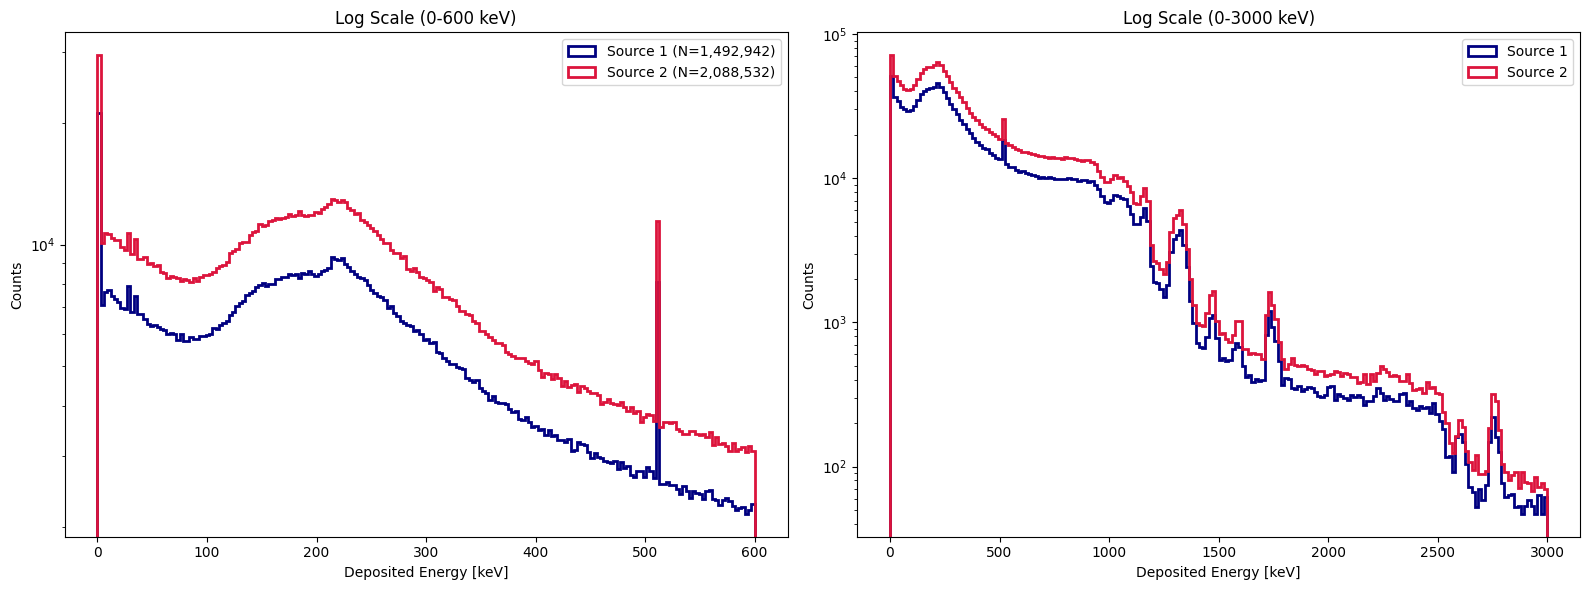

Source 1: cluster energy mean=458.7 keV, max=7877.6 keV, N=1,492,942
Source 2: cluster energy mean=457.8 keV, max=7597.3 keV, N=2,088,532


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for label, data, c in [("Source 1", data_s1, 'navy'), ("Source 2", data_s2, 'crimson')]:
    if data is None: continue
    ce = data['clusters']['energy']
    ce = ce[ce > 0]
    # 低能段 (0-600 keV)
    ax1.hist(ce, bins=200, range=(0, 600), histtype='step', color=c, lw=2, label=f'{label} (N={len(ce):,})')
    # 全能量段 (0-3000 keV)
    ax2.hist(ce, bins=200, range=(0, 3000), histtype='step', color=c, lw=2, label=f'{label}')

for ax in [ax1, ax2]:
    ax.set_xlabel('Deposited Energy [keV]')
    ax.set_ylabel('Counts')
    ax.legend(fontsize=10)

ax1.set_title('Log Scale (0-600 keV)')
ax2.set_title('Log Scale (0-3000 keV)')
ax1.set_yscale('log')
ax2.set_yscale('log')

plt.tight_layout()
plt.savefig('energy_deposition_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

for label, data in [("Source 1", data_s1), ("Source 2", data_s2)]:
    if data is None: continue
    ce = data['clusters']['energy'][data['clusters']['energy'] > 0]
    print(f"{label}: cluster energy mean={ce.mean():.1f} keV, max={ce.max():.1f} keV, N={len(ce):,}")

### energy_deposition_spectrum.png — 簇能量沉积谱

展示 DBSCAN 聚类后的每个能量簇（cluster）在 LXe 中的沉积能量分布（两图均对数纵轴）。

| 子图 | 元素 | 含义 |
|------|------|------|
| 左（对数 0–600 keV） | 蓝色/红色阶梯 | 源1/源2 簇能量直方图，低能区细节 |
| 右（对数 0–3000 keV） | 同上 | 全能量范围，对数纵轴凸显高低能尾部 |

**两个特征峰的解释**：
- **~0 keV 峰**：前向小角 Compton 散射的反冲电子沉积极小能量（物理真实）；另含约 1% 的 sub-keV 伪簇（`volume='unknown'`、位置全 NaN，Sorting/DBSCAN 伪影）。
- **~500 keV 峰**（~505–520 keV 隆起）= **511 keV 湮没线**：能量 >1.022 MeV 的 γ 在 TPC 内发生电子对产生，正电子立即湮没产生两个 511 keV 光子，经光电吸收（~42%）或 Compton（~57%）沉积 ~511 keV。是 TPC 内电子对产生的标志。

**⚠️ 重要注意（区域定义不一致）**：cluster 的体积字段记录的是 **SD 名**（`GetSDname()`）——`XenonVeto` = 物理体积 `XenonVeto1`（LXe veto 区）。**XenonVeto1 也是灵敏探测器**，本图的簇能量谱**包含 veto 区能量**（source2 中 ~21% 的簇在 XenonVeto）。而 §5 的 θ 分析只用 `XenonDetector`（TPC 区）——两者区域不一致，θ–E 配对时应只配 XenonDetector 簇。

## §4 击中位置分布 (Hit Position Distribution)

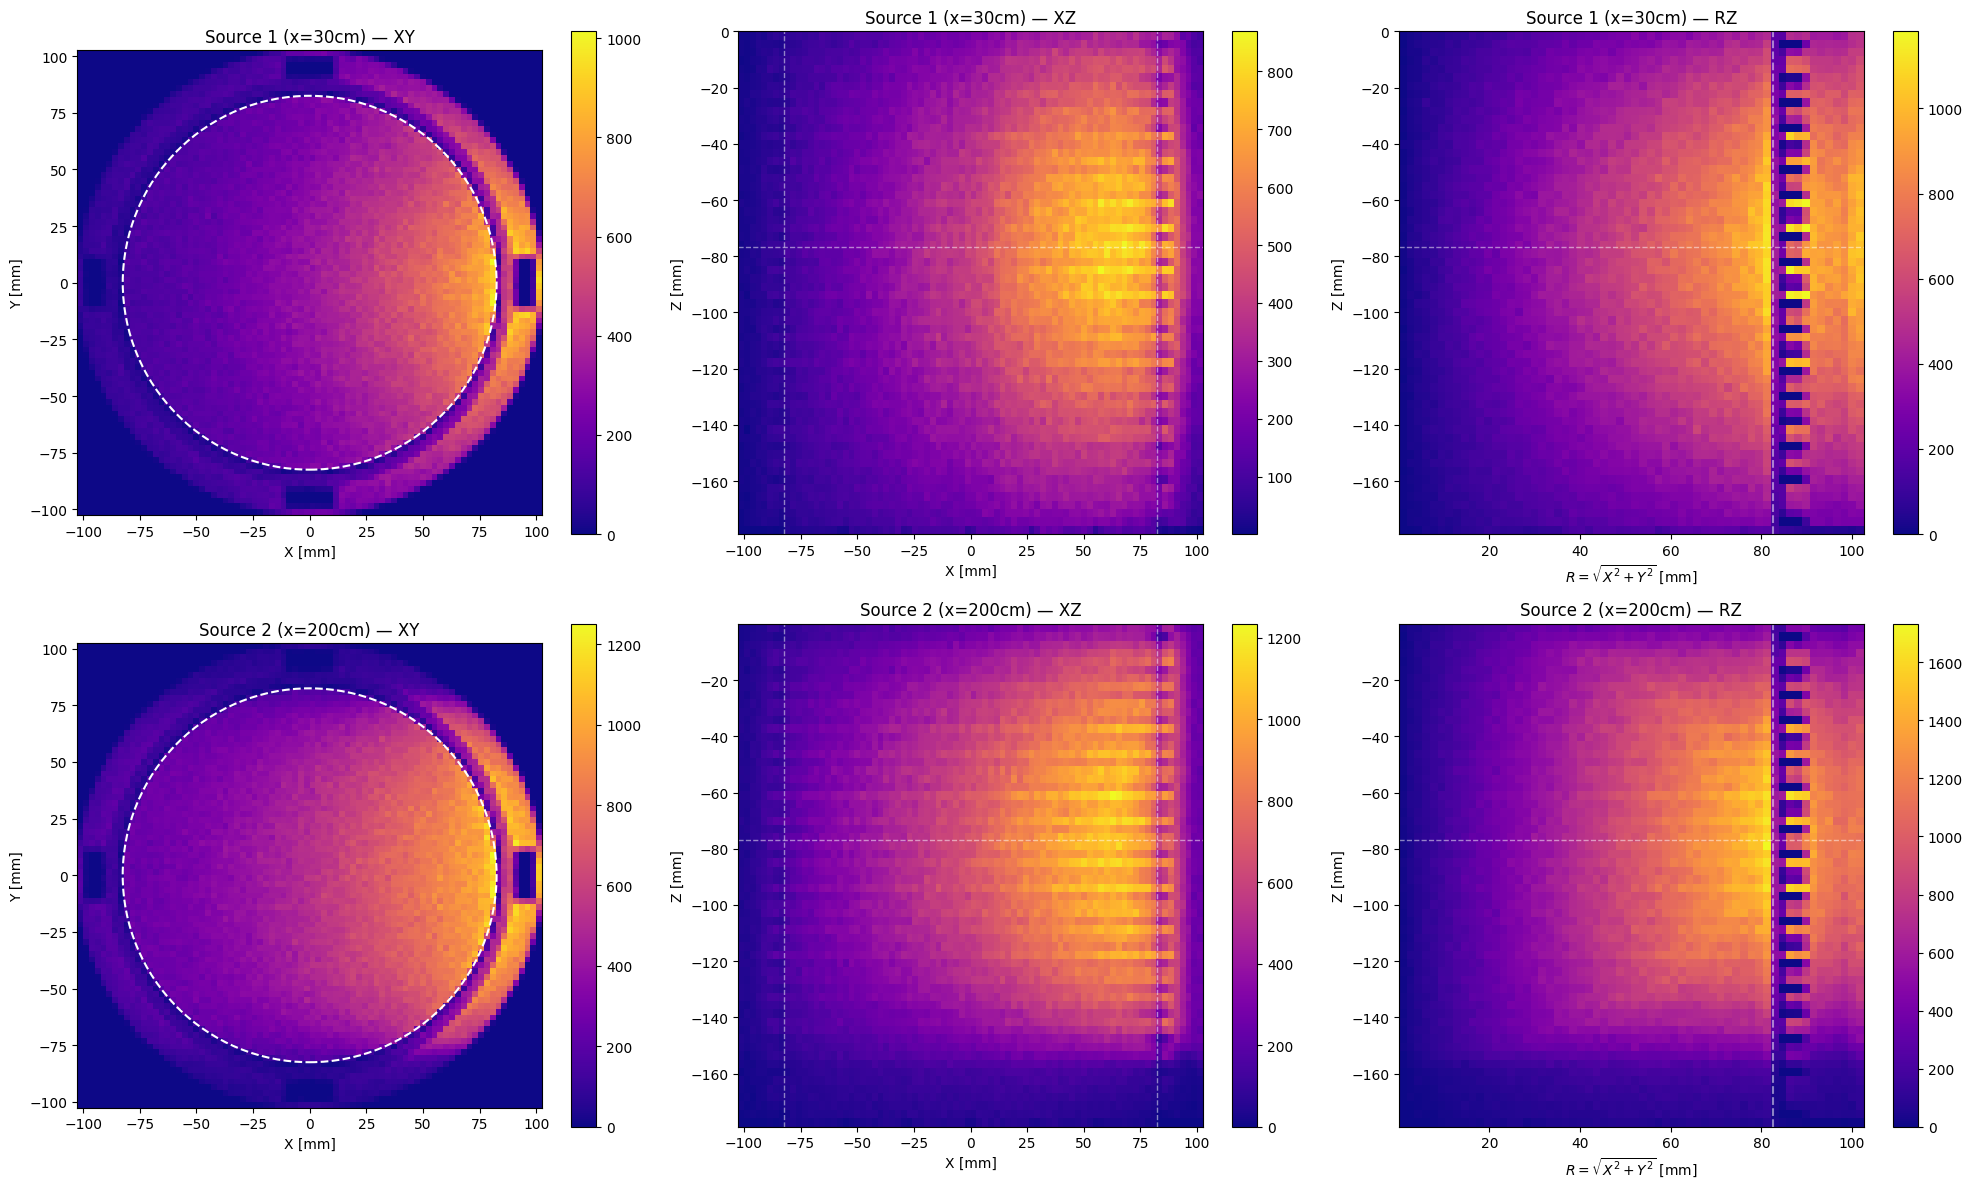

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for row, (label, data, c) in enumerate([
    ("Source 1 (x=30cm)", data_s1, 'navy'),
    ("Source 2 (x=200cm)", data_s2, 'crimson')]):
    if data is None: continue
    cl = data['clusters']
    mask = (cl['energy'] > 0) & np.isfinite(cl['er_x']) & np.isfinite(cl['er_y']) & np.isfinite(cl['er_z'])
    x, y, z = cl['er_x'][mask], cl['er_y'][mask], cl['er_z'][mask]

    # XY
    ax = axes[row, 0]
    _, _, _, im = ax.hist2d(x, y, bins=80, cmap='plasma')
    ax.add_patch(plt.Circle((0, 0), R_TPC, fill=False, color='white', lw=1.5, ls='--'))
    ax.set_xlabel('X [mm]'); ax.set_ylabel('Y [mm]')
    ax.set_title(f'{label} — XY'); ax.set_aspect('equal')
    plt.colorbar(im, ax=ax)

    # XZ
    ax = axes[row, 1]
    _, _, _, im = ax.hist2d(x, z, bins=(80, 60), cmap='plasma')
    for v in [-R_TPC, R_TPC]: ax.axvline(v, color='white', ls='--', lw=1, alpha=0.5)
    for v in [-HALF_Z_TPC, HALF_Z_TPC]: ax.axhline(v, color='white', ls='--', lw=1, alpha=0.5)
    ax.set_xlabel('X [mm]'); ax.set_ylabel('Z [mm]')
    ax.set_title(f'{label} — XZ')
    plt.colorbar(im, ax=ax)

    # RZ
    ax = axes[row, 2]
    r = np.sqrt(x**2 + y**2)
    _, _, _, im = ax.hist2d(r, z, bins=(60, 60), cmap='plasma')
    ax.axvline(R_TPC, color='white', ls='--', lw=1.5, alpha=0.5)
    for v in [-HALF_Z_TPC, HALF_Z_TPC]: ax.axhline(v, color='white', ls='--', lw=1, alpha=0.5)
    ax.set_xlabel(r'$R = \sqrt{X^2+Y^2}$ [mm]'); ax.set_ylabel('Z [mm]')
    ax.set_title(f'{label} — RZ')
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('hit_position_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### hit_position_distribution.png — 击中位置分布

展示簇的能量加权位置 $(x_c, y_c, z_c)$ 在 TPC 内的空间分布。

| 列 | 含义 |
|------|------|
| XY | 束流横截面，白色虚线圆表示 TPC 内边界（R=82.5 mm） |
| XZ | 沿束流方向 ($x$) 与纵向 ($z$) 的投影，白色虚线框标注 TPC 边界 |
| RZ | 径向 $R=\sqrt{X^2+Y^2}$ vs $Z$ 分布，反映圆柱对称性 |

**物理意义**：源1（上排）因源近距离近（x=30cm）且 ±18° 锥角，击中弥散在 TPC 远侧（+x 方向）和全 Z 范围；源2（下排）因源远（x=200cm）且 ±0.1° 准直，击中集中在束斑附近。RZ 图中击中局限在 $R \leq 82.5$ mm 内，验证几何边界正确。

## §5 偏转角分析 (Deflection Angle, TPC 内)

$$\theta = \angle(p_{in}, p_{out}) = \arccos\!\left(\frac{p_{in}\cdot p_{out}}{|p_{in}|\,|p_{out}|}\right)$$

**p_{in}, p_{out}均来自 ROOT `mcTree` 的 gammaComp* 分支**：
- $p_{in}$ = 该步**入射动量** = `gammaCompPrePx/Py/Pz`（PreStep 动量，散射前的真实入射方向）
- $p_{out}$ = **出射动量** = `gammaCompPx/Py/Pz`（PostStep 动量，散射后的方向）

**key points**：
- **只取 LXe TPC 内的相互作用**：过滤 `gammaCompVol == "XenonDetector"`
- **每一次** TPC 内相互作用都算（不限定首次）
- γ 之前在别处（空气/环/veto）散射过 n 次、这是它在 TPC 内的第 n+1 次，也照算（$p_{in}$ 记录的是当时的真实入射方向）
- **不能用** `primaryPx/Py/Pz` 当入射方向（那只对"从未散射过的 γ"成立）
- **数据必须从 ROOT 读**：h5 的 gammaComp 数据集只有 x/y/z/px/py/pz/t，**没有体积、没有入射动量**

**output**：
- `θ_first`：每事件 TPC 内首次（时间最早）相互作用的偏转角
- `θ_all`：TPC 内每次相互作用的偏转角（`theta_s1/s2`）
- 单重（TPC 内仅 1 次 Compton）/ 多重（≥2 次）分开统计



/opt/miniconda3/envs/XENONnT_2022.06.2/lib/python3.8/site-packages/awkward/_backends.py:58: RuntimeWarning: invalid value encountered in true_divide
  return getattr(ufunc, method)(*args, **kwargs)


  Source 1: 配到 TPC 簇比例 = 100.0%
  Source 2: 配到 TPC 簇比例 = 100.0%

=== Source 1 (TPC内 Compton, volume==XenonDetector) ===
  总事件 714,736 | 有>=1次TPC内Compton: 442,778 (61.9%)
  单重 197,359 (27.6%) | 多重 245,419 (34.3%)
  θ_first[全部]: N=442,778, mean=64.0°, median=54.7°
  θ_first[单重]: N=197,359, mean=73.5°, median=67.6°
  θ_first[多重]: N=245,419, mean=56.3°, median=47.7°
  θ_all(TPC内每次): N=856,234, mean=67.5°, median=58.8°

=== Source 2 (TPC内 Compton, volume==XenonDetector) ===
  总事件 930,959 | 有>=1次TPC内Compton: 649,632 (69.8%)
  单重 277,382 (29.8%) | 多重 372,250 (40.0%)
  θ_first[全部]: N=649,632, mean=63.7°, median=54.4°
  θ_first[单重]: N=277,382, mean=74.0°, median=68.5°
  θ_first[多重]: N=372,250, mean=56.1°, median=47.5°
  θ_all(TPC内每次): N=1,282,956, mean=67.4°, median=58.8°


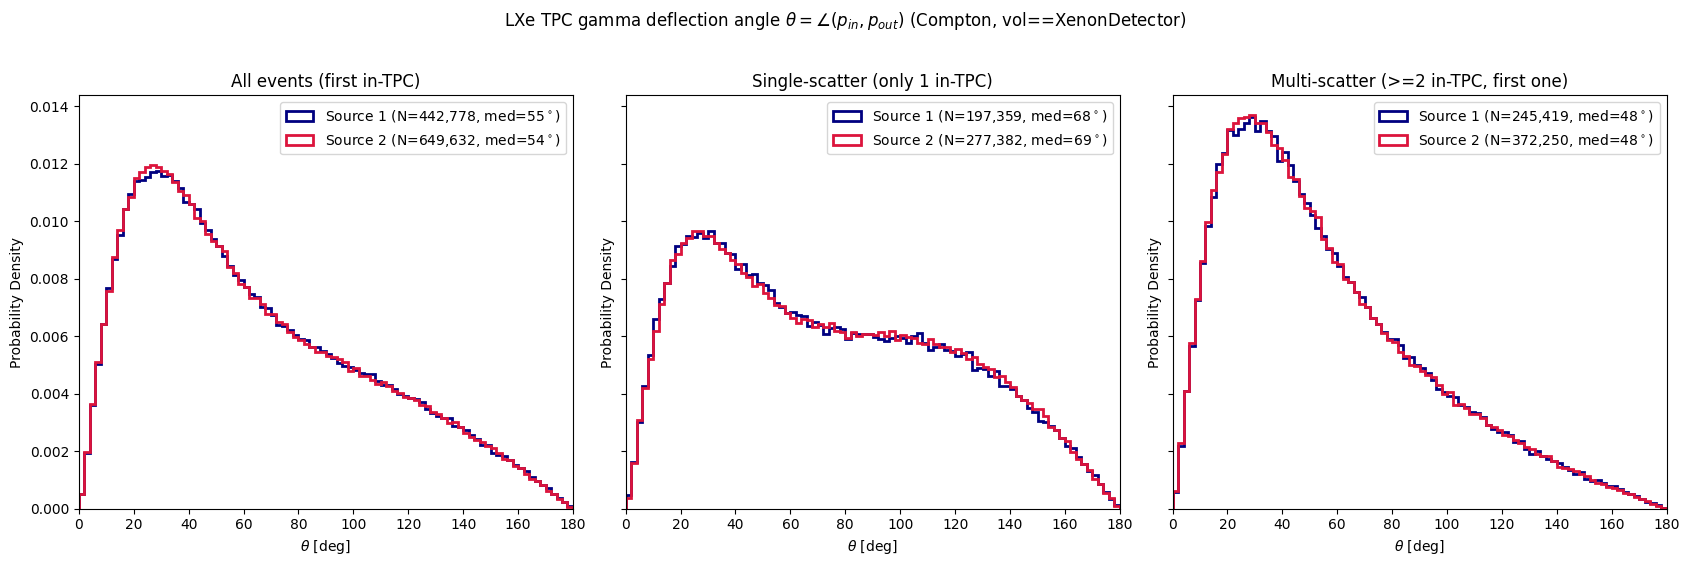

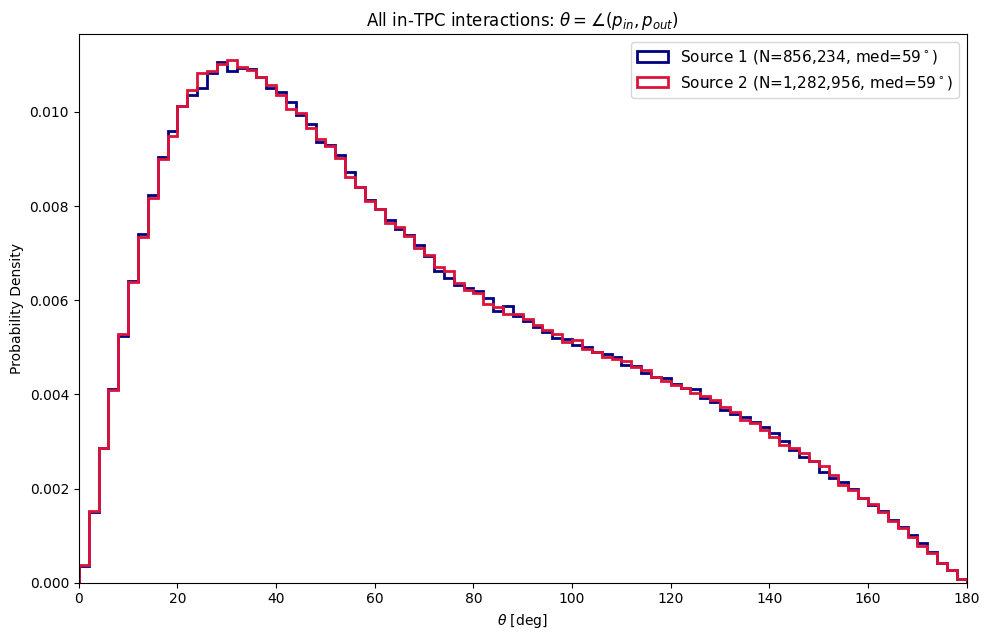

In [6]:
def compute_inTPC_theta(root_path, vol_filter='XenonDetector'):
    """theta = angle(p_in, p_out) for EVERY gamma Compton inside the LXe TPC.
    p_in = gammaCompPrePx/Py/Pz (PreStep 入射动量), p_out = gammaCompPx/Py/Pz (PostStep 出射动量).
    Data read directly from ROOT mcTree (h5 的 gammaComp 缺体积/入射动量字段).
    ev_all 返回的是 TREE 行号 (0..N-1), 不是 G4 eventId!
    """
    t = uproot.open(str(root_path))['mcTree']
    nGC  = np.asarray(t['nGammaComp'].array())
    vol  = t['gammaCompVol'].array()
    prex = t['gammaCompPrePx'].array(); prey = t['gammaCompPrePy'].array(); prez = t['gammaCompPrePz'].array()
    px   = t['gammaCompPx'].array();    py   = t['gammaCompPy'].array();    pz   = t['gammaCompPz'].array()
    tm   = t['gammaCompT'].array()

    in_tpc = (vol == vol_filter)                 # jagged bool: TPC 内记录
    cnt = np.asarray(ak.sum(in_tpc, axis=1))     # 每事件 TPC 内 Compton 次数

    dot = prex*px + prey*py + prez*pz
    np_ = np.sqrt(prex**2 + prey**2 + prez**2)
    np2 = np.sqrt(px**2 + py**2 + pz**2)
    den = np_ * np2
    th  = np.degrees(np.arccos(np.clip(
        np.asarray(ak.flatten(np.where(den > 0, dot/den, np.nan))), -1, 1)))

    cnts_all = np.asarray(nGC)
    fevt = np.repeat(np.arange(len(cnts_all)), cnts_all)   # TREE 行号
    ftm  = np.asarray(ak.flatten(tm))
    fin  = np.asarray(ak.flatten(in_tpc))

    ok = fin & np.isfinite(th)
    th_all = th[ok]          # TPC 内每次相互作用的偏转角
    ev_all = fevt[ok]        # 对应 TREE 行号
    tm_all = ftm[ok]

    order = np.lexsort((tm_all, ev_all))         # 每事件 TPC 内首次(时间最早)
    sfe   = ev_all[order]; sfth = th_all[order]
    fm    = np.concatenate([[True], sfe[1:] != sfe[:-1]])
    th_first = sfth[fm]

    cnt_ev = cnt[cnt > 0]
    return dict(th_all=th_all, ev_all=ev_all, tm_all=tm_all, th_first=th_first,
                cnt=cnt, cnt_ev=cnt_ev)


def pair_theta_energy(res, data, vol_filter='XenonDetector'):
    """把每条 TPC 内记录与同事件中时间最近的 cluster（反冲电子）配对。
    ⚠️ 关键: gammaComp 的 ev_all 是 TREE 行号, 而 cluster/primary 的 eventId 是
       G4 事件号(不同!)。必须用 events 表(树序)把行号映射到 G4 eventId。
    ⚠️ 单位修复 (2026-08-07): clusters['er_t'] 是秒(Sorting.py 除以 scale_to_ns 后), 而 gammaCompT 是 ns; 旧代码直接比较→配对随机, 现 er_t×1e9 统一到 ns。
    ⚠️ 只配 vol_filter (XenonDetector=TPC) 的簇 —— 排除 XenonVeto/XenonVeto1
       (LXe veto) 区的簇 (cluster 体积字段=SD名+bytes, 'XenonVeto'=物理'XenonVeto1')。
    返回 每条记录的 (theta, E_dep, E_init)。"""
    cl = data['clusters']; p = data['primaries']
    row_to_evtid = data['events']['eventId']     # 树行号 -> G4 eventId (events 表是树序)
    vol_bytes = vol_filter.encode()              # h5 er_volume 是 bytes 对象数组
    cm = (cl['energy'] > 0) & (cl['er_volume'] == vol_bytes)
    c_evt = cl['eventId'][cm]; c_t = cl['er_t'][cm] * 1e9; c_e = cl['energy'][cm]  # 秒→ns (2026-08-07 单位修复)
    evt_cl = defaultdict(list)
    for i in range(len(c_evt)):
        evt_cl[int(c_evt[i])].append(i)
    evt_cl = {k: np.asarray(v) for k, v in evt_cl.items()}
    evt_to_p = {int(p['eventId'][i]): i for i in range(len(p))}

    th = res['th_all']; row = res['ev_all']; tt = res['tm_all']
    e_dep = np.full(len(th), np.nan)
    e_init = np.full(len(th), np.nan)
    for i in range(len(th)):
        eid = int(row_to_evtid[row[i]])          # TREE 行号 -> G4 eventId
        idxs = evt_cl.get(eid)
        if idxs is None or len(idxs) == 0:
            continue
        best = idxs[np.argmin(np.abs(c_t[idxs] - tt[i]))]
        e_dep[i] = c_e[best]
        pi = evt_to_p.get(eid)
        if pi is not None:
            e_init[i] = p['primaryEnergy'][pi]
    return e_dep, e_init


# ---- 计算 TPC 内偏转角 ----
res_s1 = compute_inTPC_theta(Path("../result/gamma_source1_1e6_clean.root"))
res_s2 = compute_inTPC_theta(Path("../result/gamma_source2_1e6_clean.root"))

# 每条记录 (theta, E_dep, E_init) —— 供 §5 后续 θ–E 关联图使用
theta_s1, e_s1, e_init_s1 = res_s1['th_all'], *pair_theta_energy(res_s1, data_s1)
theta_s2, e_s2, e_init_s2 = res_s2['th_all'], *pair_theta_energy(res_s2, data_s2)

# 配对诊断: 配到 TPC 簇的比例
for label, e_ in [("Source 1", e_s1), ("Source 2", e_s2)]:
    print(f"  {label}: 配到 TPC 簇比例 = {100*np.isfinite(e_).mean():.1f}%")

for label, res in [("Source 1", res_s1), ("Source 2", res_s2)]:
    cnt = res['cnt']; tf = res['th_first']; ce = res['cnt_ev']
    print(f"\n=== {label} (TPC内 Compton, volume==XenonDetector) ===")
    print(f"  总事件 {len(cnt):,} | 有>=1次TPC内Compton: {(cnt>0).sum():,} ({(cnt>0).mean()*100:.1f}%)")
    print(f"  单重 {(cnt==1).sum():,} ({(cnt==1).mean()*100:.1f}%) | 多重 {(cnt>=2).sum():,} ({(cnt>=2).mean()*100:.1f}%)")
    for k, v in [("全部", tf), ("单重", tf[ce==1]), ("多重", tf[ce>=2])]:
        print(f"  θ_first[{k}]: N={len(v):,}, mean={v.mean():.1f}°, median={np.median(v):.1f}°")
    print(f"  θ_all(TPC内每次): N={len(res['th_all']):,}, mean={res['th_all'].mean():.1f}°, median={np.median(res['th_all']):.1f}°")

# ---- θ_first: 全部 / 单重 / 多重 ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, (key, title) in zip(axes, [
        ('all', 'All events (first in-TPC)'),
        ('single', 'Single-scatter (only 1 in-TPC)'),
        ('multi', 'Multi-scatter (>=2 in-TPC, first one)')]):
    for res, label, c in [(res_s1, 'Source 1', 'navy'), (res_s2, 'Source 2', 'crimson')]:
        tf = res['th_first']; ce = res['cnt_ev']
        if key == 'all':      v = tf
        elif key == 'single': v = tf[ce == 1]
        else:                 v = tf[ce >= 2]
        ax.hist(v, bins=90, range=(0, 180), histtype='step', color=c, lw=2, density=True,
                label=f'{label} (N={len(v):,}, med={np.median(v):.0f}$^\\circ$)')
    ax.set_xlabel(r'$\theta$ [deg]'); ax.set_ylabel('Probability Density')
    ax.set_title(title); ax.legend(fontsize=10); ax.set_xlim(0, 180)
plt.suptitle(r'LXe TPC gamma deflection angle $\theta=\angle(p_{in},p_{out})$ (Compton, vol==XenonDetector)', y=1.02)
plt.tight_layout()
plt.savefig('theta_first_inTPC.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- θ_all: TPC 内每次相互作用 ----
from matplotlib.ticker import FuncFormatter, PercentFormatter
fig, ax = plt.subplots(figsize=(10, 6.5))
for res, label, c in [(res_s1, 'Source 1', 'navy'), (res_s2, 'Source 2', 'crimson')]:
    v = res['th_all']
    ax.hist(v, bins=90, range=(0, 180), histtype='step', color=c, lw=2, density=True,
            label=f'{label} (N={len(v):,}, med={np.median(v):.0f}$^\\circ$)')
ax.set_xlabel(r'$\theta$ [deg]'); ax.set_ylabel('Probability Density')
ax.set_title(r'All in-TPC interactions: $\theta=\angle(p_{in},p_{out})$')
ax.legend(fontsize=11); ax.set_xlim(0, 180)
plt.tight_layout()
plt.savefig('theta_all_inTPC.png', dpi=150, bbox_inches='tight')
plt.show()

### theta_first_inTPC.png 

θ = ∠(p_in, p_out) 来自 **volume==XenonDetector**（LXe TPC）内的 Compton 相互作用，p_in/p_out 均来自 ROOT 的 gammaComp* 分支。

| 子图 | 含义 |
|------|------|
| All | 全部事件 TPC 内首次相互作用的 θ（中位数 ~54°） |
| Single | 单重散射（TPC 内仅 1 次）首次 θ（中位数 ~68°） |
| Multi | 多重散射（≥2 次）首次 θ（中位数 ~48°） |

**物理意义**：
- **单重 vs 多重显著不同**：小角前向散射的 γ 保留能量继续穿越 TPC → 更易再次散射（多重）；大角散射的 γ 转向/降能后更易逃逸（单重）。
- **Source1 与 Source2 几乎重合**：θ 相对各 γ 自身入射方向定义，与源几何无关 → 自洽性检验 ✓

In [ ]:
# =====================================================================
# theta_reco: reconstructed-cluster double-scatter angle
# ---------------------------------------------------------------------
# Selection/reconstruction uses only HDF5 reconstructed clusters:
#   - TPC ER clusters: energy > 0 and er_volume == b"XenonDetector"
#   - r1/r2: the earliest two clusters after ordering by er_t
#   - theta_reco = angle(r1 - nominal_source_position, r2 - r1)
# ROOT gammaComp supplies only the matched first-in-TPC theta_true.
# TrackID and gammaComp X/Y/Z are not used for selection or reconstruction.
# =====================================================================

from plot_theta_reco_vs_true import (
    compute_theta_reco_true,
    plot_core_gaussian_fwhm,
    plot_difference,
    plot_reco_vs_true,
)

theta_true_s1, theta_reco_s1 = compute_theta_reco_true(
    Path("../result/gamma_source1_1e6_clean.root"), H5_S1, SRC1_POS
)
theta_true_s2, theta_reco_s2 = compute_theta_reco_true(
    Path("../result/gamma_source2_1e6_clean.root"), H5_S2, SRC2_POS
)

resolution_results = {
    "Source 1": (theta_true_s1, theta_reco_s1),
    "Source 2": (theta_true_s2, theta_reco_s2),
}

for label, (theta_true, theta_reco) in resolution_results.items():
    valid = np.isfinite(theta_true) & np.isfinite(theta_reco)
    delta = theta_reco[valid] - theta_true[valid]
    absolute = np.abs(delta)
    print(f"=== {label} (HDF5 reconstructed clusters, N={valid.sum():,}) ===")
    print(
        f"  theta_true/reco median="
        f"{np.median(theta_true[valid]):.2f}/{np.median(theta_reco[valid]):.2f} deg"
    )
    print(
        f"  delta: mean={np.mean(delta):.3f} deg; mean abs={np.mean(absolute):.3f} deg; "
        f"median abs={np.median(absolute):.3f} deg"
    )
    print(
        f"  |delta| containment 68/90="
        f"{np.quantile(absolute, 0.68):.3f}/{np.quantile(absolute, 0.90):.3f} deg; "
        f"corr={np.corrcoef(theta_true[valid], theta_reco[valid])[0, 1]:.4f}"
    )

plot_reco_vs_true(resolution_results)
plot_difference(resolution_results)
core_measurements = plot_core_gaussian_fwhm(resolution_results)

from IPython.display import Image as IPythonImage, display

display(IPythonImage(filename="plot/theta_reco_vs_true.png"))
display(IPythonImage(filename="plot/theta_reco_minus_true_hist_log.png"))
display(IPythonImage(filename="plot/theta_reco_minus_true_gaussian_fwhm.png"))


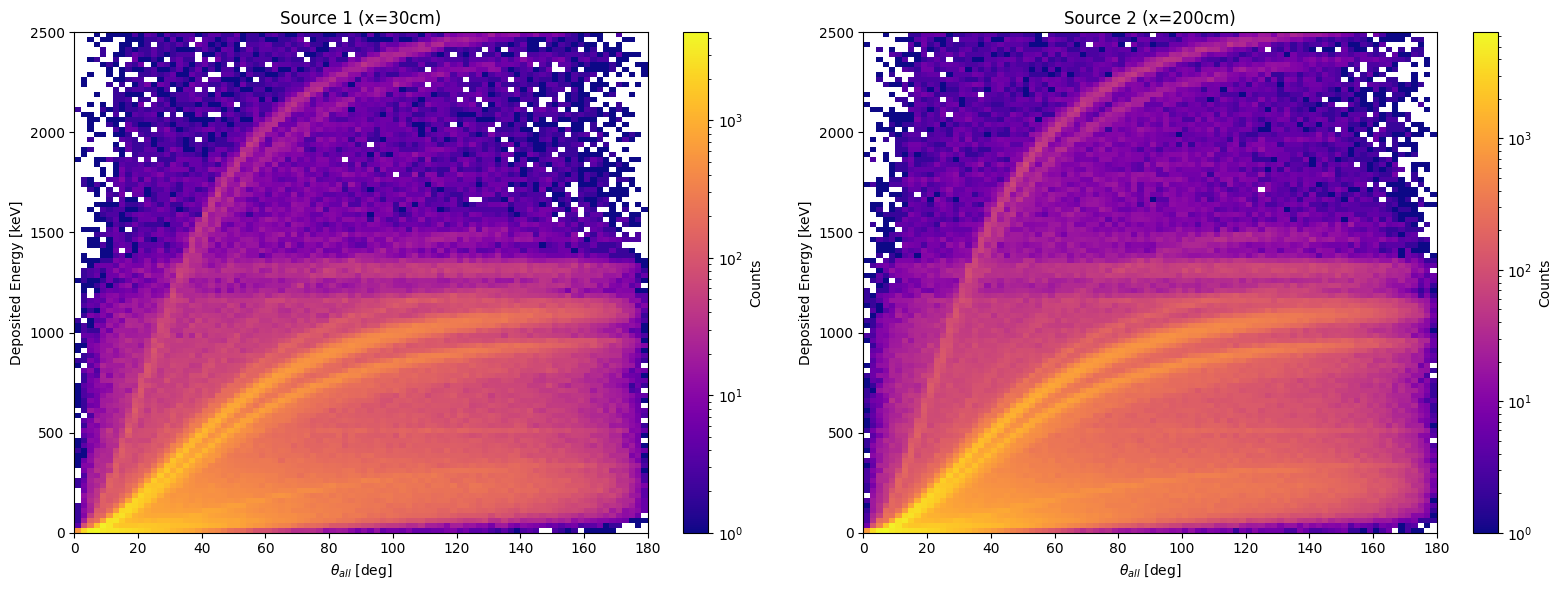

In [ ]:
# ---- θ_all vs deposited energy (per in-TPC interaction) ----
# 与 deflection_vs_energy_vs_einit.png 统一范围: E_dep 0-2500 keV, θ 0-180°
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, theta, e_dep, label in [
    (axes[0], theta_s1, e_s1, 'Source 1 (x=30cm)'),
    (axes[1], theta_s2, e_s2, 'Source 2 (x=200cm)')]:
    m = np.isfinite(e_dep)
    h = ax.hist2d(theta[m], e_dep[m], bins=(90, 100), range=[[0, 180], [0, 2500]],
                   cmap='plasma', norm=LogNorm())
    ax.set_xlabel(r'$\theta_{all}$ [deg]')
    ax.set_ylabel('Deposited Energy [keV]')
    ax.set_title(label)
    plt.colorbar(h[3], ax=ax, label='Counts')

plt.tight_layout()
plt.savefig('deflection_vs_energy.png', dpi=150, bbox_inches='tight')
plt.show()

### deflection_angle_vs_energy.png — 偏转角 vs 沉积能量（TPC 内每次相互作用）

2D 直方图：每条 TPC 内记录的 θ_all（横轴）vs 配对的反冲电子簇能量 E_dep（纵轴，对数色阶）。

- **θ_all = ∠(p_in, p_out)** 为 TPC 内**每一次** Compton 相互作用的偏转角（`theta_s1/s2`）。
- **范围与 `deflection_vs_energy_vs_einit.png` 统一**：θ 0–180°，E_dep 0–2500 keV（bin = 2° × 25 keV），避免不同范围造成歧义。

**配对方式**：每条 gammaComp 记录与该事件中时间最近的 TPC（XenonDetector）簇（反冲电子）配对。

**物理意义**：Compton 散射 θ 越大 → E_dep 越大（对确定 E_init）。数据沿理论 Compton 曲线分布可验证配对正确性。

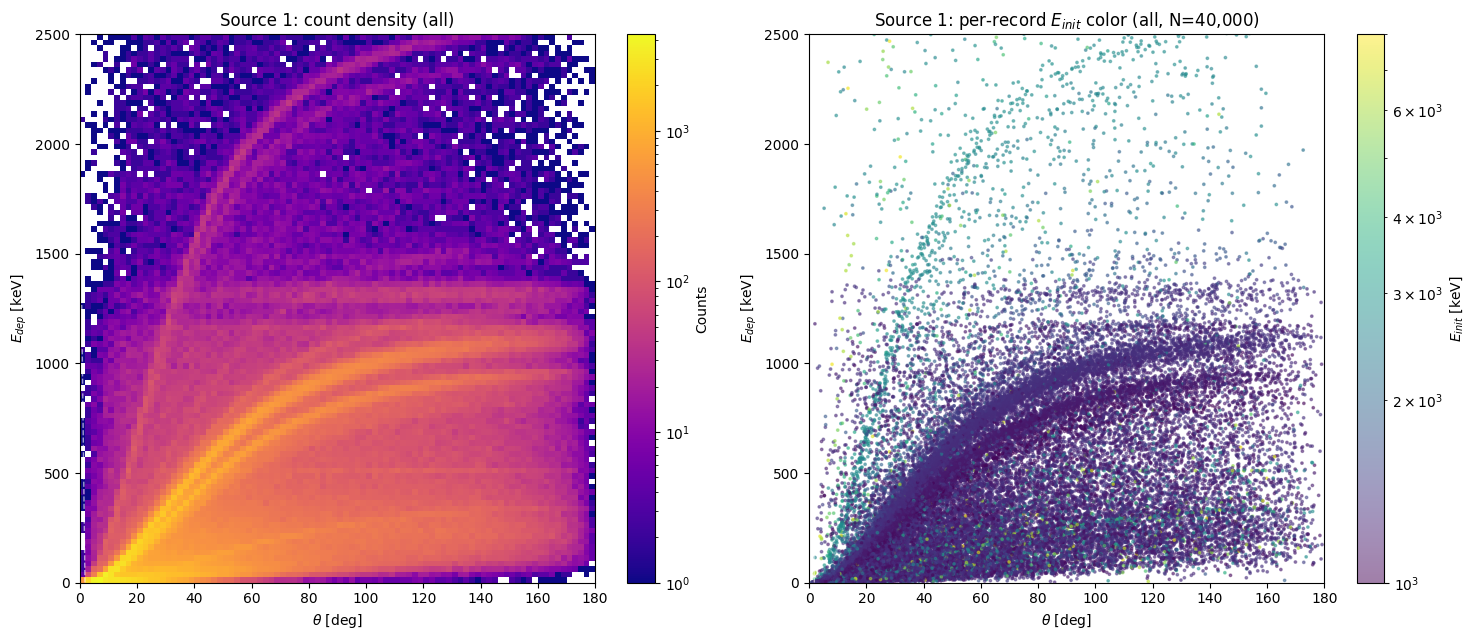

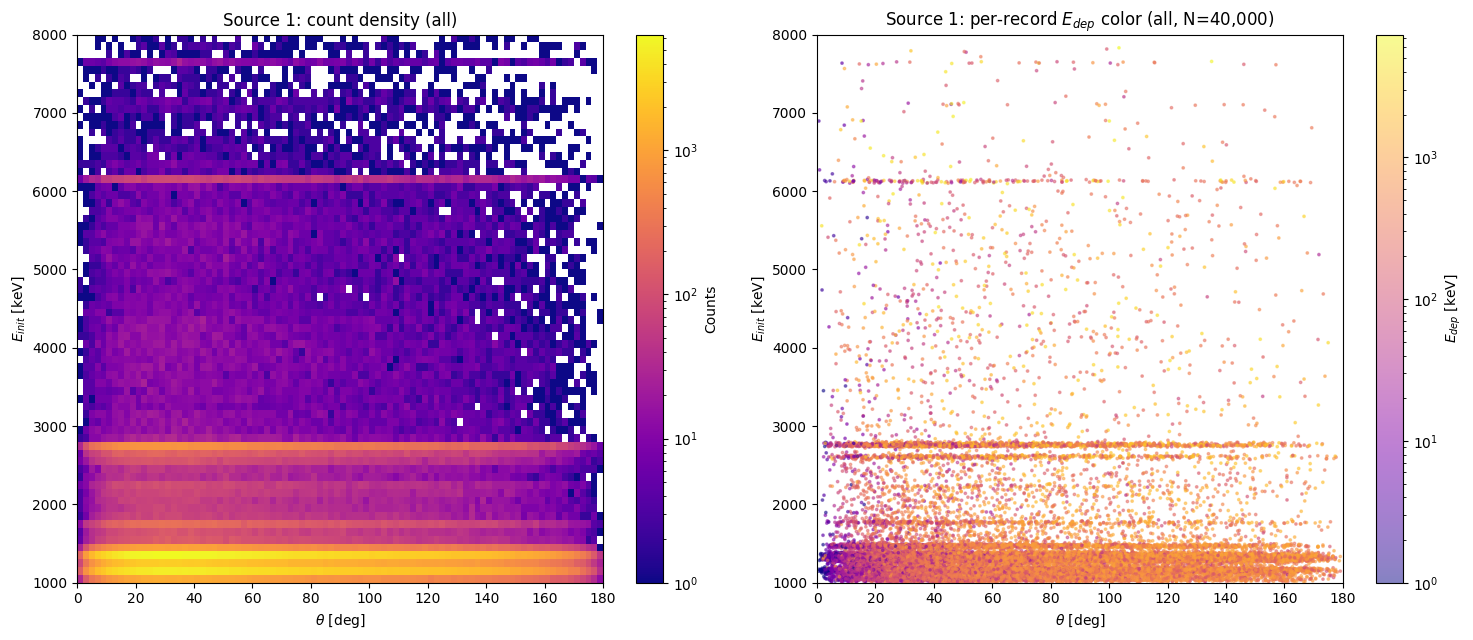

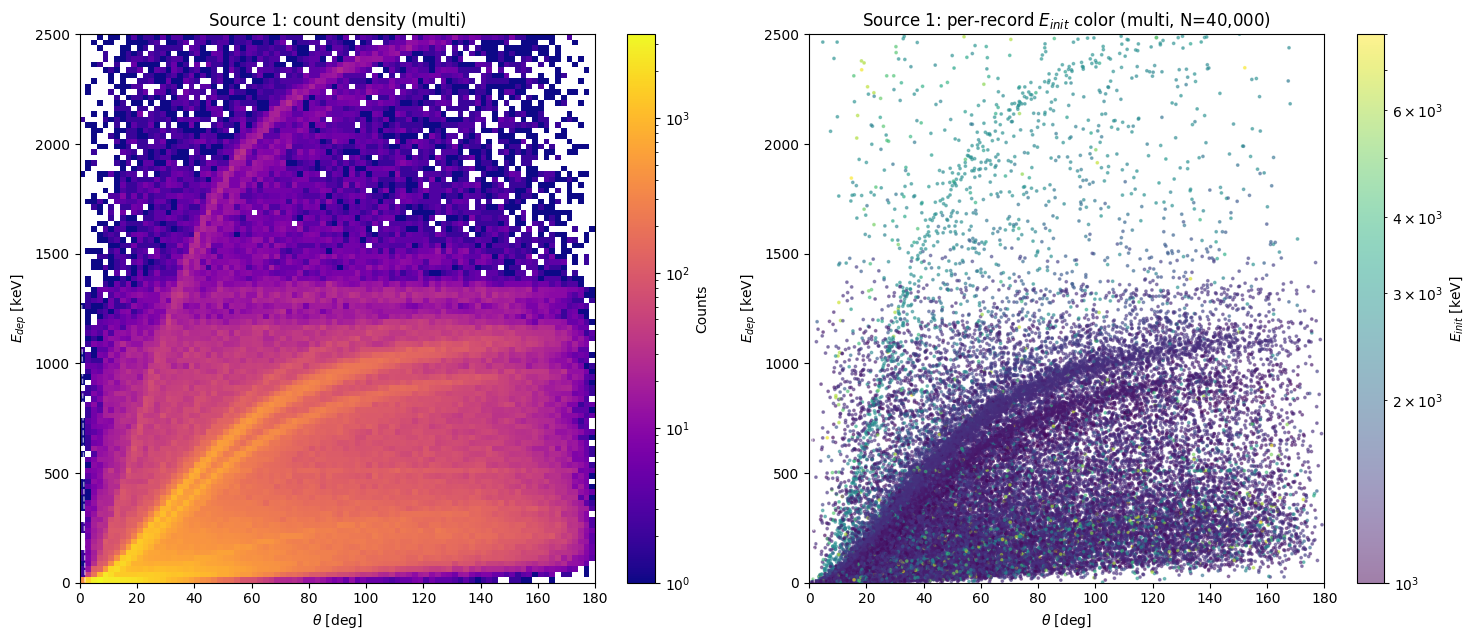

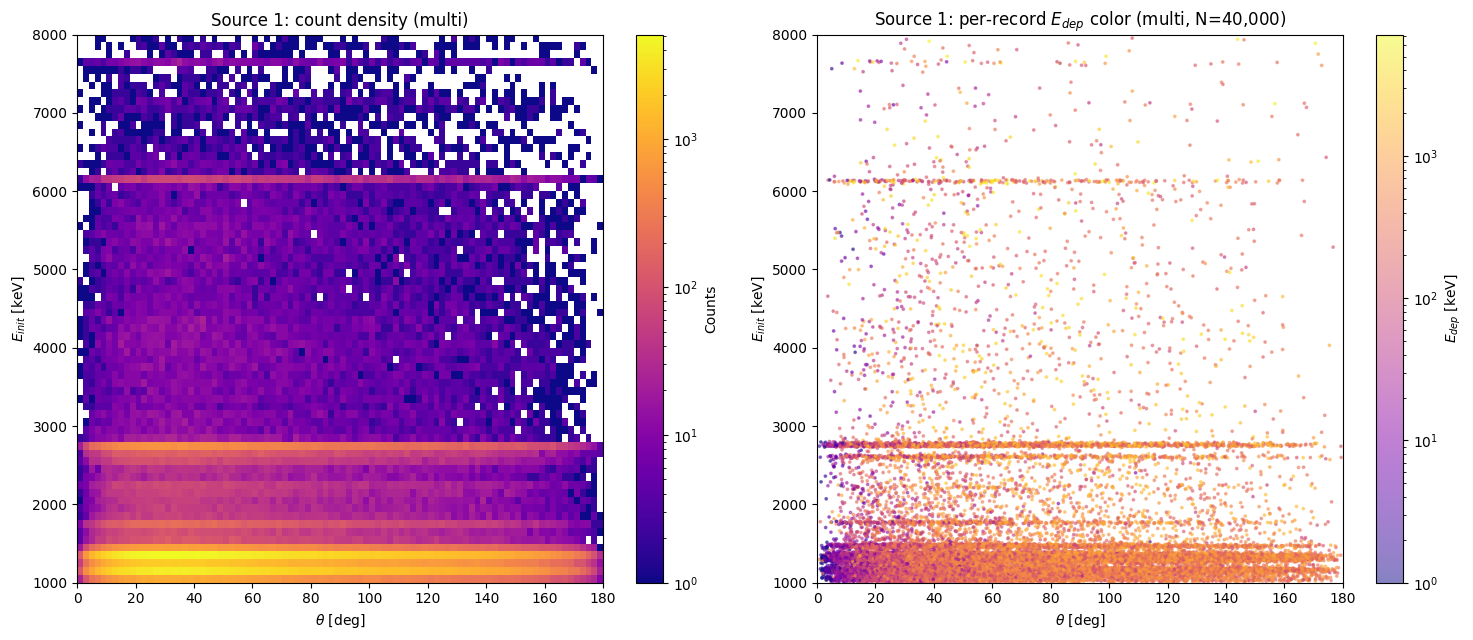

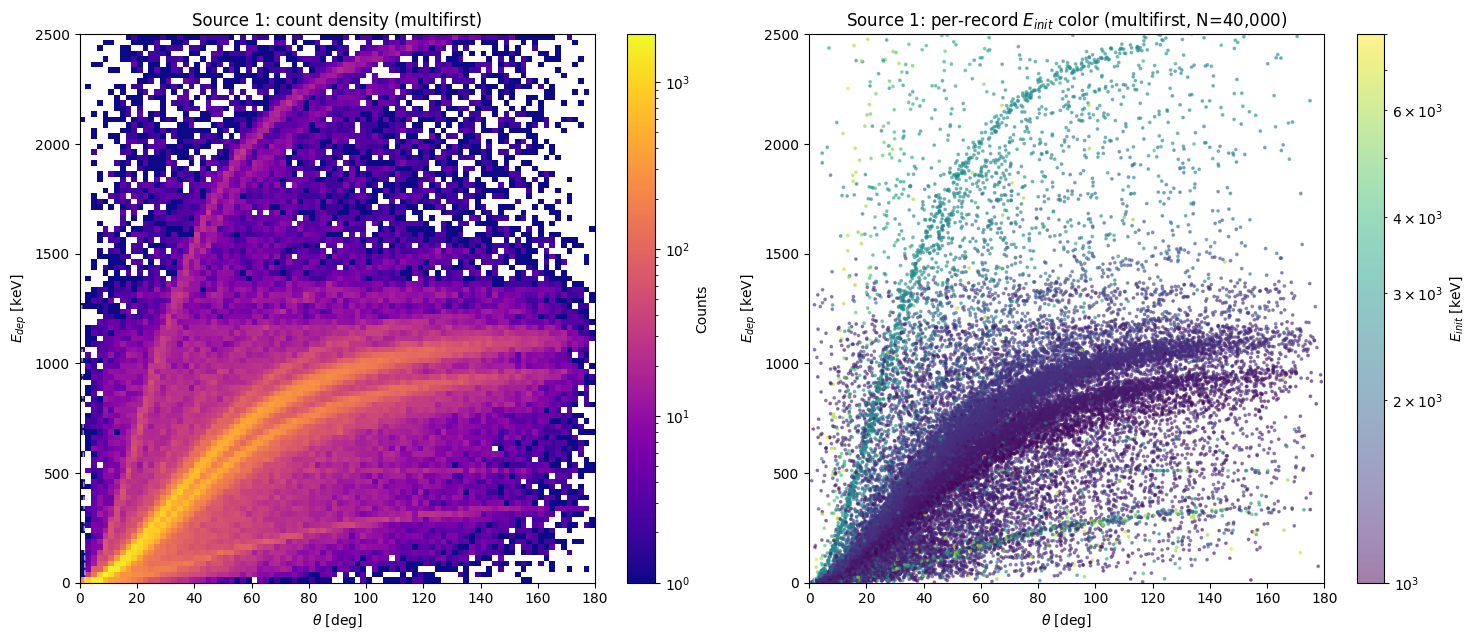

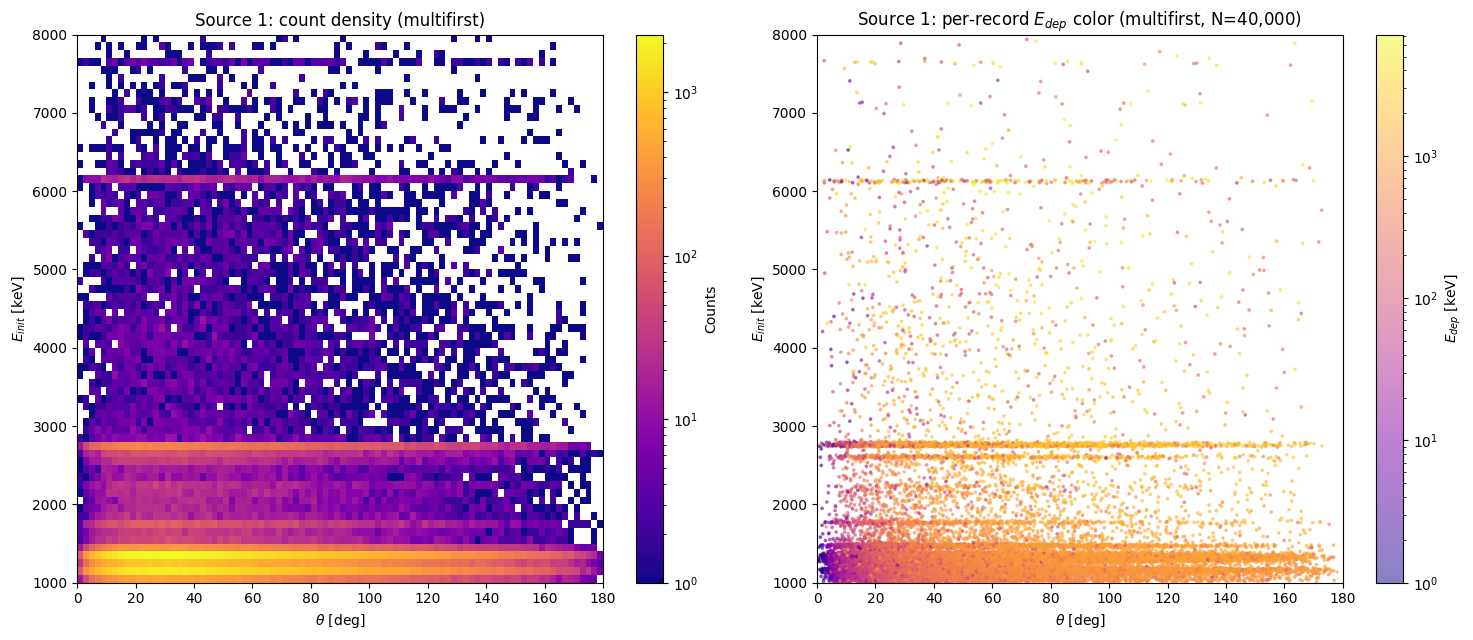

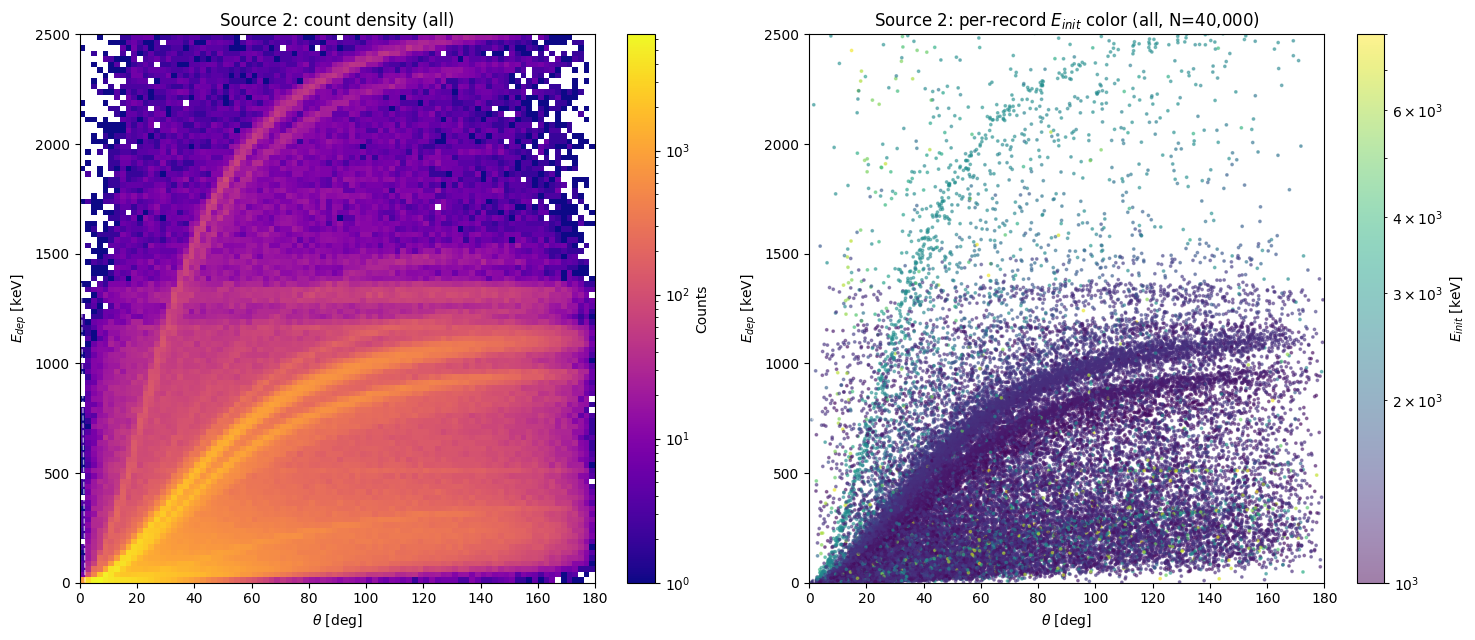

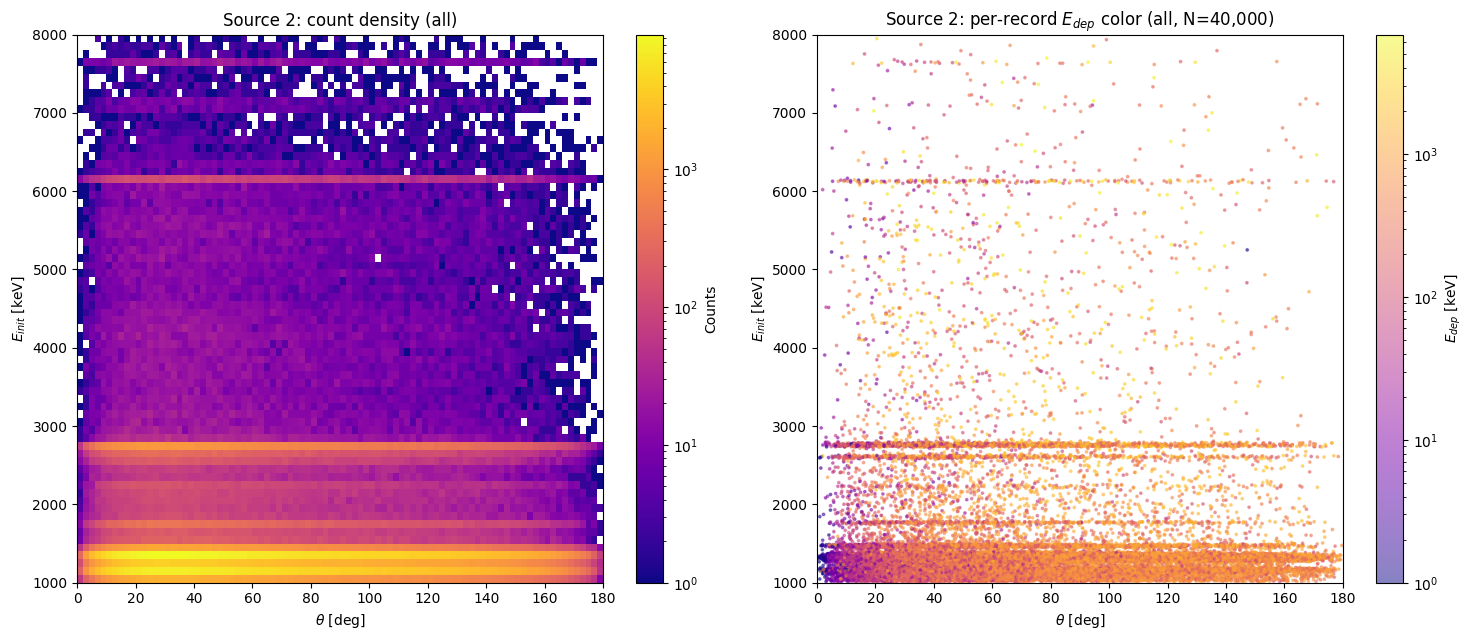

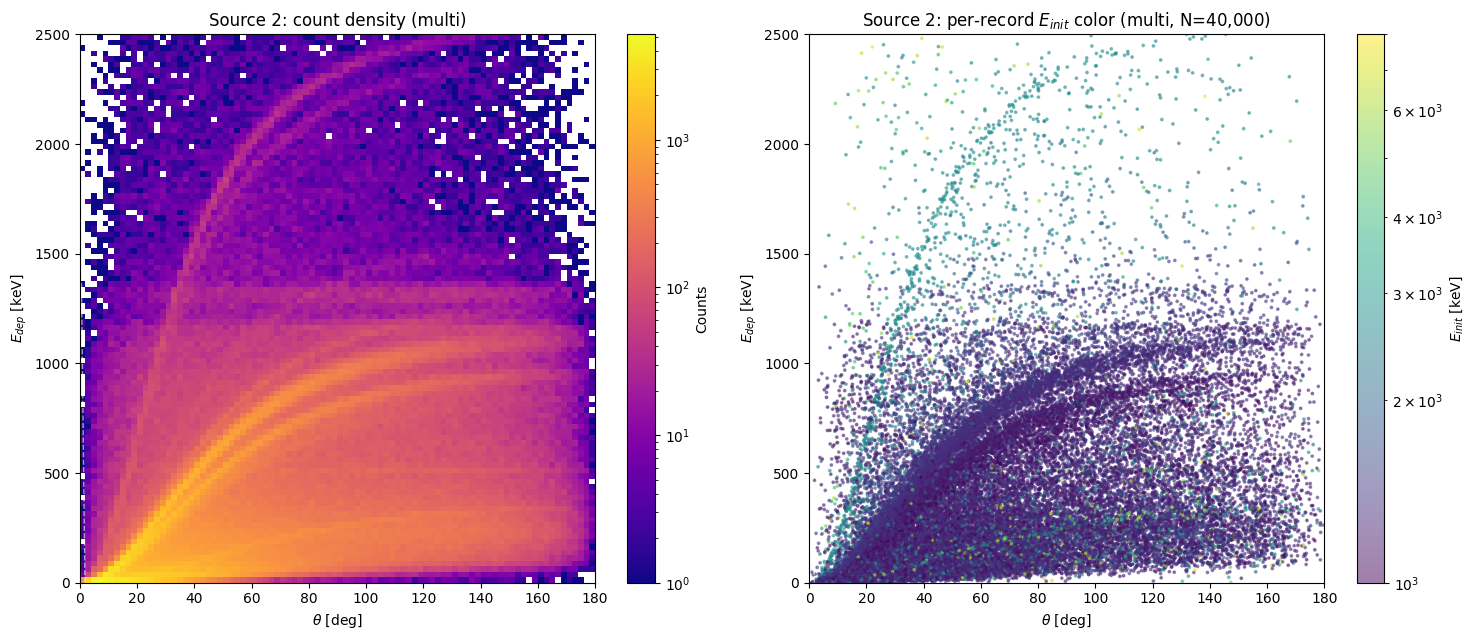

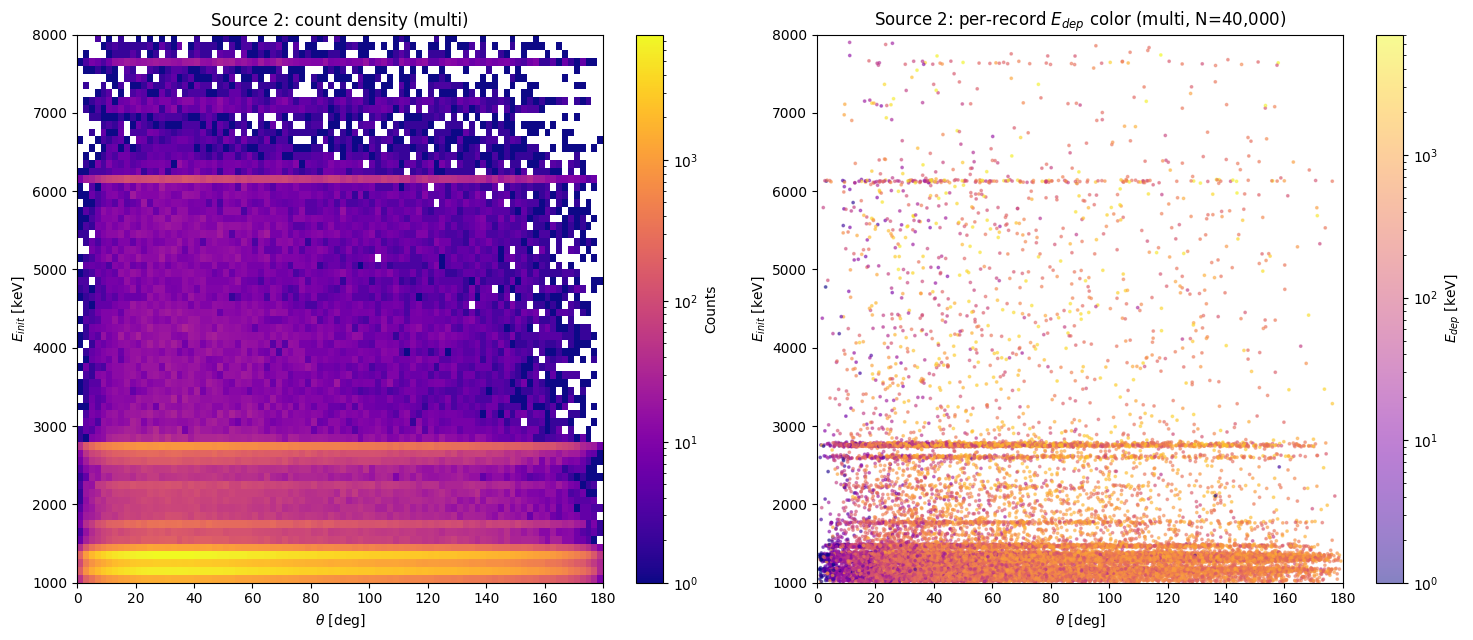

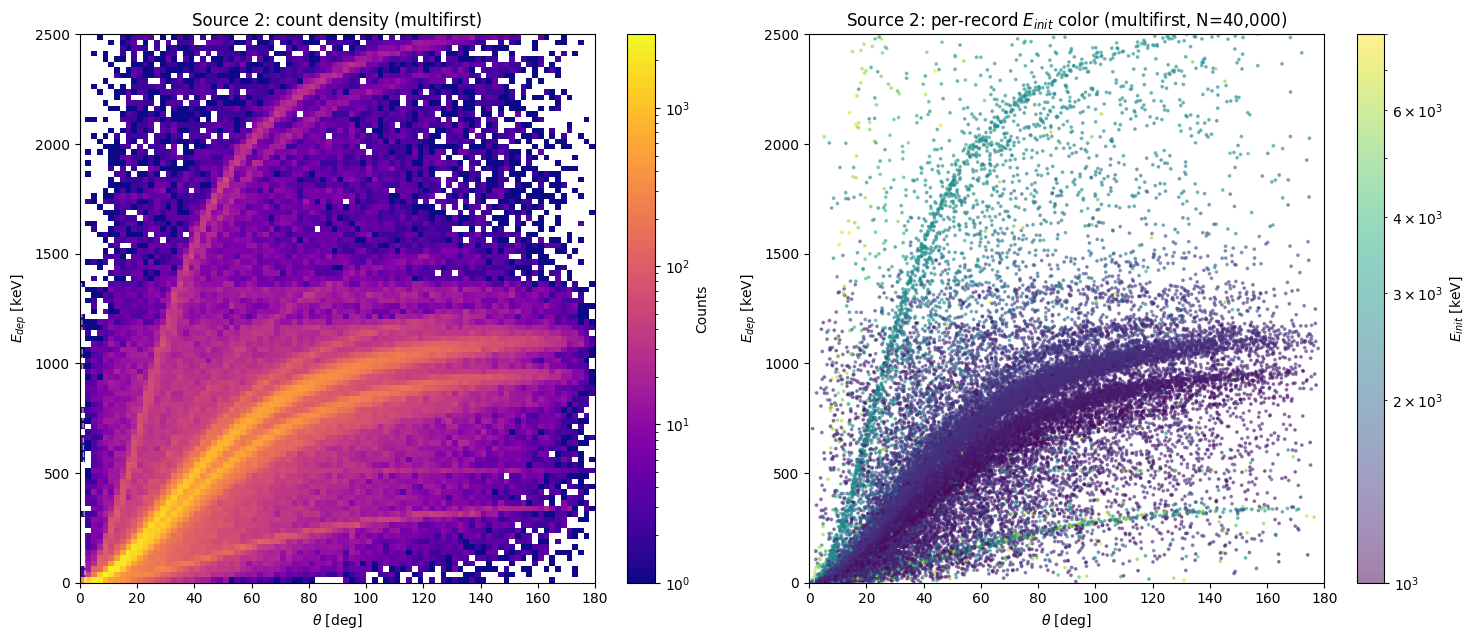

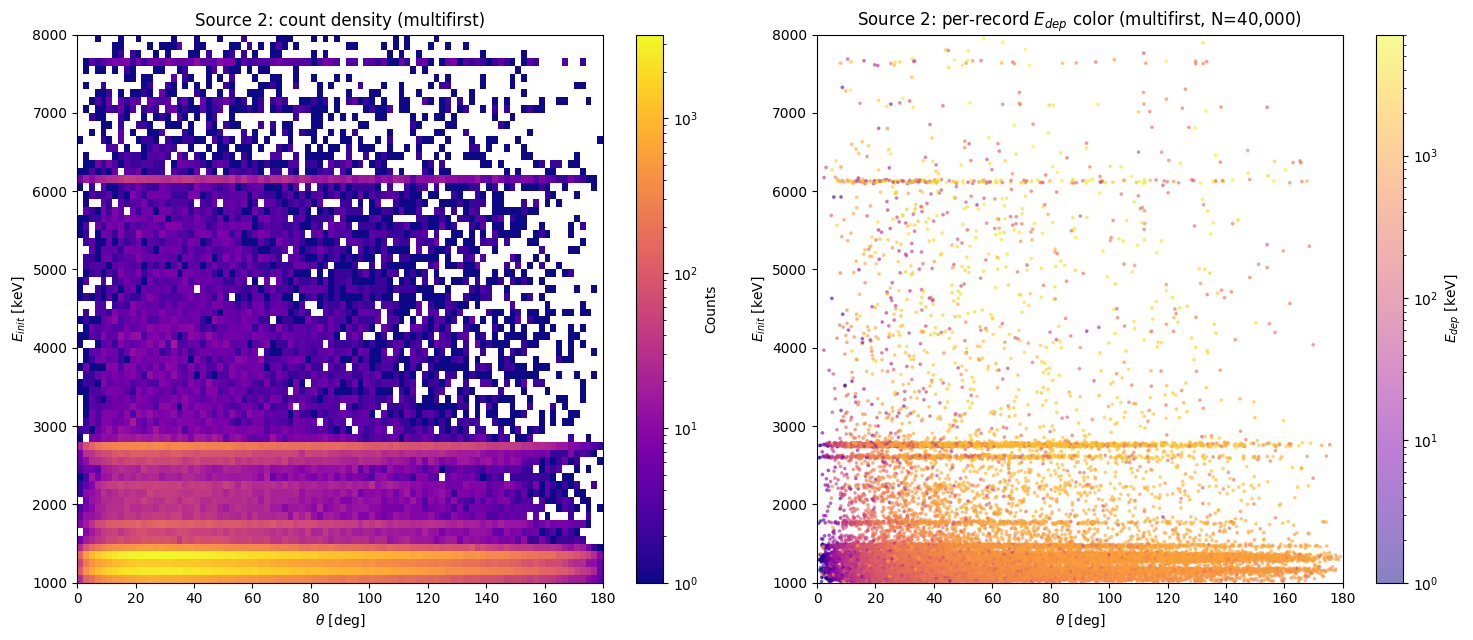

Source 1: all=856,228 | multi=658,875 | multifirst=245,419
Source 2: all=1,282,951 | multi=1,005,574 | multifirst=372,250


In [16]:
# =====================================================================
# §5b  θ–E 关联图：3 种样本 × 2 种纵轴 = 6 张图 / 源
# ---------------------------------------------------------------------
# 样本 (sample):
#   all        = 全部事件, 每条 TPC 内记录 (θ_all)
#   multi      = 仅多重散射事件 (TPC 内 Compton>=2) 的所有记录 (θ_all)
#   multifirst = 仅多重散射事件, 每事件取时间最早一条 (θ_first)
# 纵轴 (axis):
#   E_dep      = 配对反冲电子簇能量   (bin 2°×25 keV, 0–2500 keV)
#   E_init     = 初级 γ 能量          (bin 2°×100 keV, 1000–8000 keV)
# 每张图 3 面板: 计数密度 / 每 bin 平均 / 逐记录着色
#   仅 E_dep 纵轴图叠加 Compton 理论曲线: 只画下边界 E0=1 MeV 与上边界 E0=8 MeV
# 输出: 每个源 6 张 png (文件名带 _s1/_s2 后缀)
# =====================================================================
from matplotlib.colors import LogNorm

def first_multi(res, theta, e_dep, e_init):
    """多重散射事件中, 每事件取时间最早一条 (θ_first)."""
    cnt_rec = res['cnt'][res['ev_all']]
    multi = cnt_rec >= 2
    ev_m = res['ev_all'][multi]; tm_m = res['tm_all'][multi]
    th_m = theta[multi]; ed_m = e_dep[multi]; ei_m = e_init[multi]
    order = np.lexsort((tm_m, ev_m))               # 按(事件, 时间)排序
    se = ev_m[order]; sth = th_m[order]; sed = ed_m[order]; sei = ei_m[order]
    fm = np.concatenate([[True], se[1:] != se[:-1]])  # 每事件取第一条
    return sth[fm], sed[fm], sei[fm]

def _compton_curve_edep(ax, e0_list=(1000, 8000)):
    """E_dep 纵轴: 固定 E_init=E0 的 E_dep(θ) Compton 理论曲线.
    只画谱的上下边界: E0=1 MeV (Compton 带下边界) 和 E0=8 MeV (上边界).
    公式: E_dep = E0²·(1-cosθ)/(m_ec² + E0·(1-cosθ));
    θ=180° 时最大 E_dep_max = 2·E0²/(m_ec² + 2·E0).
    """
    for e0_keV in e0_list:
        e_dep_max = e0_keV**2 * 2 * M_E_C2 / (M_E_C2 + 2 * e0_keV)  # 2E0²/(m+2E0)
        e_dep_th = np.linspace(1, e_dep_max, 200)
        ratio = M_E_C2 * e_dep_th / (e0_keV * (e0_keV - e_dep_th))  # = 1-cosθ
        valid = (ratio >= -1) & (ratio <= 1)
        costh = 1 - ratio[valid]
        th = np.degrees(np.arccos(np.clip(costh, -1, 1)))
        ax.plot(th, e_dep_th[valid], 'w--', lw=1, alpha=0.6)
        idx = len(th) // 2
        if idx < len(th):
            ax.annotate(f'{e0_keV/1000:.0f} MeV', (th[idx], e_dep_th[valid][idx]),
                        color='white', fontsize=8, alpha=0.7)

def plot_theta_E_series(src_label, theta, e_dep, e_init, res, tag='s1'):
    cnt_rec = res['cnt'][res['ev_all']]
    multi = cnt_rec >= 2
    m_ok = np.isfinite(e_dep) & np.isfinite(e_init)

    # ---- 3 种样本 ----
    th_fm, ed_fm, ei_fm = first_multi(res, theta, e_dep, e_init)
    m_fm = np.isfinite(ed_fm) & np.isfinite(ei_fm)
    datasets = {
        'all':        (theta[m_ok],          e_dep[m_ok],          e_init[m_ok]),
        'multi':      (theta[multi & m_ok],  e_dep[multi & m_ok],  e_init[multi & m_ok]),
        'multifirst': (th_fm[m_fm],          ed_fm[m_fm],          ei_fm[m_fm]),
    }

    bins_theta = np.linspace(0, 180, 91)          # 2°/bin
    bins_edep  = np.linspace(0, 2500, 101)        # 25 keV/bin
    bins_einit = np.linspace(1000, 8000, 71)      # 100 keV/bin
    suffix = {'all': '', 'multi': '_multiscatter', 'multifirst': '_multifirst'}
    rng = np.random.default_rng(42)

    for sample, (th_s, ed_s, ei_s) in datasets.items():
        # ---------- 纵轴 E_dep ----------
        fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(15, 6.5))
        h = ax1.hist2d(th_s, ed_s, bins=(bins_theta, bins_edep), cmap='plasma', norm=LogNorm(vmin=1))
        ax1.set_xlabel(r'$\theta$ [deg]'); ax1.set_ylabel(r'$E_{dep}$ [keV]')
        ax1.set_title(f'{src_label}: count density ({sample})')
        plt.colorbar(h[3], ax=ax1, label='Counts')

        # H, _, _ = np.histogram2d(th_s, ed_s, bins=(bins_theta, bins_edep))
        # Hw, _, _ = np.histogram2d(th_s, ed_s, bins=(bins_theta, bins_edep), weights=ei_s)
        # with np.errstate(divide='ignore', invalid='ignore'):
        #     mean_other = np.where(H > 0, Hw / np.maximum(H, 1), np.nan)
        # im = ax2.pcolormesh(bins_theta, bins_edep, mean_other.T, cmap='viridis',
        #                     norm=LogNorm(vmin=1000, vmax=8000))
        # ax2.set_xlabel(r'$\theta$ [deg]'); ax2.set_ylabel(r'$E_{dep}$ [keV]')
        # ax2.set_title(f'{src_label}: mean $E_{{init}}$ per bin ({sample})')
        # plt.colorbar(im, ax=ax2, label='mean $E_{init}$ [keV]')

        idx_sub = rng.choice(np.arange(len(th_s)), size=min(40000, len(th_s)), replace=False)
        sc = ax3.scatter(th_s[idx_sub], ed_s[idx_sub], c=ei_s[idx_sub],
                         cmap='viridis', s=3, alpha=0.5, norm=LogNorm(vmin=1000, vmax=8000))
        ax3.set_xlabel(r'$\theta$ [deg]'); ax3.set_ylabel(r'$E_{dep}$ [keV]')
        ax3.set_title(f'{src_label}: per-record $E_{{init}}$ color ({sample}, N={len(idx_sub):,})')
        plt.colorbar(sc, ax=ax3, label='$E_{init}$ [keV]')

        # 只叠加谱边界理论曲线: E0=1 MeV (下界) 与 E0=8 MeV (上界)
        for ax in [ax1, ax3]:
            _compton_curve_edep(ax, e0_list=(1000, 8000))
            ax.set_xlim(0, 180); ax.set_ylim(0, 2500)
        plt.tight_layout()
        plt.savefig(f'deflection_vs_energy_vs_einit{suffix[sample]}_{tag}.png', dpi=150, bbox_inches='tight')
        plt.show()

        fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(15, 6.5))
        h = ax1.hist2d(th_s, ei_s, bins=(bins_theta, bins_einit), cmap='plasma', norm=LogNorm(vmin=1))
        ax1.set_xlabel(r'$\theta$ [deg]'); ax1.set_ylabel(r'$E_{init}$ [keV]')
        ax1.set_title(f'{src_label}: count density ({sample})')
        plt.colorbar(h[3], ax=ax1, label='Counts')

        # H, _, _ = np.histogram2d(th_s, ei_s, bins=(bins_theta, bins_einit))
        # Hw, _, _ = np.histogram2d(th_s, ei_s, bins=(bins_theta, bins_einit), weights=ed_s)
        # with np.errstate(divide='ignore', invalid='ignore'):
        #     mean_other = np.where(H > 0, Hw / np.maximum(H, 1), np.nan)
        # im = ax2.pcolormesh(bins_theta, bins_einit, mean_other.T, cmap='plasma', norm=LogNorm(vmin=1))
        # ax2.set_xlabel(r'$\theta$ [deg]'); ax2.set_ylabel(r'$E_{init}$ [keV]')
        # ax2.set_title(f'{src_label}: mean $E_{{dep}}$ per bin ({sample})')
        # plt.colorbar(im, ax=ax2, label='mean $E_{dep}$ [keV]')

        idx_sub = rng.choice(np.arange(len(th_s)), size=min(40000, len(th_s)), replace=False)
        sc = ax3.scatter(th_s[idx_sub], ei_s[idx_sub], c=ed_s[idx_sub],
                         cmap='plasma', s=3, alpha=0.5, norm=LogNorm(vmin=1))
        ax3.set_xlabel(r'$\theta$ [deg]'); ax3.set_ylabel(r'$E_{init}$ [keV]')
        ax3.set_title(f'{src_label}: per-record $E_{{dep}}$ color ({sample}, N={len(idx_sub):,})')
        plt.colorbar(sc, ax=ax3, label='$E_{dep}$ [keV]')

        for ax in [ax1, ax2, ax3]:
            ax.set_xlim(0, 180); ax.set_ylim(1000, 8000)
        plt.tight_layout()
        plt.savefig(f'deflection_vs_einit{suffix[sample]}_{tag}.png', dpi=150, bbox_inches='tight')
        plt.show()


plot_theta_E_series('Source 1', theta_s1, e_s1, e_init_s1, res_s1, tag='s1')
plot_theta_E_series('Source 2', theta_s2, e_s2, e_init_s2, res_s2, tag='s2')

for label, th, ed, ei, res in [("Source 1", theta_s1, e_s1, e_init_s1, res_s1),
                               ("Source 2", theta_s2, e_s2, e_init_s2, res_s2)]:
    cnt_rec = res['cnt'][res['ev_all']]
    multi = cnt_rec >= 2
    th_fm, ed_fm, ei_fm = first_multi(res, th, ed, ei)
    n_all = np.isfinite(ed) & np.isfinite(ei)
    n_multi = multi & n_all
    n_fm = np.isfinite(ed_fm) & np.isfinite(ei_fm)
    print(f"{label}: all={n_all.sum():,} | multi={n_multi.sum():,} | multifirst={n_fm.sum():,}")

| 仅多重+首次（θ_first） | `deflection_vs_energy_vs_einit_multifirst_{s}.png` | `deflection_vs_einit_multifirst_{s}.png` |

**样本定义**：
- `all` = 全部事件，每条 TPC 内记录的 θ_all（单重+多重混合）；
- `multi` = 仅多重散射事件（TPC 内 Compton≥2）的所有相互作用（θ_all）；
- `multifirst` = 多重散射事件中每事件取时间最早一条（θ_first）。

**理论曲线（2026-08-07 精简）**：
- **仅 E_dep 纵轴图**叠加白色虚线，且只画**谱的上下边界**：$E_0=1$ MeV（Compton 带下界）与 $E_0=8$ MeV（上界），中间 2/3/5 MeV 三条已删除。
- **E_init 纵轴图不加理论曲线**（原固定 E_dep 反解的曲线已删除）：E_init 轴本身是输入谱投影，加曲线反而干扰水平亮带的观察。

### Compton 理论曲线：

**出发点（单次 Compton 散射的运动学）**：入射光子能量 $E_0$，散射角 $\theta$，反冲电子（被探测）能量

$$E_{\mathrm{dep}} = E_0 - E' = \frac{E_0^2\,(1-\cos\theta)}{m_e c^2 + E_0\,(1-\cos\theta)}, \qquad E' = \frac{E_0}{1+\frac{E_0}{m_ec^2}(1-\cos\theta)}$$

这是由能量、动量守恒 + 电子静止初态直接推出的**精确运动学关系**（无近似）。特征：
- $\theta=0°$ 时 $E_{\mathrm{dep}}=0$（擦过式散射，电子几乎不动）；$\theta=180°$ 时最大，$E_{\mathrm{dep}}^{\max} = \dfrac{2E_0^2}{m_ec^2+2E_0}$。
- 对给定 $E_0$，$E_{\mathrm{dep}}(\theta)$ 单调上升——大角散射沉积更多能量。

**E_dep 纵轴图（`_compton_curve_edep`）——固定 E_init=E₀，画 E_dep(θ)**
- 由来：把上面公式对 $E_0 \in \{1, 8\}$ MeV 逐点求值，得到 2 条白色虚线。画法：先给 $E_{\mathrm{dep}}$，由 $1-\cos\theta = \dfrac{m_ec^2\,E_{\mathrm{dep}}}{E_0(E_0-E_{\mathrm{dep}})}$ 反解 $\theta$ 逐点描线。
- 意义/作用：它们是"若 γ 的入射能量是 $E_0$，则该 (θ, E_dep) 必须落在哪条线上"的**理论预言**。数据是 1–8 MeV 连续谱，应当填满这两条线围成的"Compton 带"：
  - **1 MeV 线 = 下边界**（最低入射能量 → 任何记录不可能低于它）；
  - **8 MeV 线 = 上边界**（最高入射能量）。
- 数据贴着这个带 ⇒ ① θ 与 E_dep 的**配对运动学正确**（配对无误）；② 记录的 θ 确实是 γ 的散射角。中间 2/3/5 MeV 曲线不提供新信息（只是带内细分），删除后图面更干净。
- ⚠️ 2026-08-07 已修正端点 bug：原误写为 $E_0\cdot 2m/(m+2E_0)$（缺 $E_0$ 因子），曲线被截断在 ~400–500 keV；正确终点为 $2E_0^2/(m+2E_0)$，8 MeV 线在 θ≈14° 处超出 2500 keV 顶界（物理正确）。

**为什么 E_init 纵轴图不加理论曲线**：
- 原固定 $E_{\mathrm{dep}}$ 反解的 $E_0(\theta)=\dfrac{E_{\mathrm{dep}}\,x+\sqrt{E_{\mathrm{dep}}^2x^2+4x\,E_{\mathrm{dep}}\,m_ec^2}}{2x}$（$x=1-\cos\theta$）在物理上等价于 E_dep 图的同一关系在 (θ, E_init) 平面的投影，并不提供额外信息。
- E_init 图最有用的特征是**输入谱的水平亮带**（86.8% 记录集中在 1–1.6 MeV），叠加向下弯的曲线反而遮挡这条带。故删除，只保留 E_dep 图上的边界曲线。

**物理意义**：
- 数据集中在 1/8 MeV 理论曲线围成的"Compton 带"上 → 验证 θ 与 E_dep 的运动学关联（也验证记录配对正确性）。
- 中/右图显示另一种能量在 θ–E 平面上的粗粒结构与逐记录结构：低 E_dep 大 θ 区来自低能 γ；高能 γ 覆盖更大的 θ–E 空间。
- 连续谱下 E_dep 单独决定不了 θ（同一 E_dep 对应不同 E_init 的不同 θ）——中/右图直观展示这个简并。
- Source1 与 Source2 的 θ–E 结构应一致（θ 相对各 γ 自身入射方向定义），可用作自洽性检验。

## §6 统计总结

In [10]:
# ---- 统计总结表 ----
print("=== 统计总结 ===")
for label, data, res in [("Source 1", data_s1, res_s1), ("Source 2", data_s2, res_s2)]:
    if data is None:
        continue
    e, c, p = data['events'], data['clusters'], data['primaries']
    cnt = res['cnt']
    print(f"\n--- {label} ---")
    print(f"  事件数: {len(e):,}")
    print(f"  Mean total Edep/event [keV]: {np.nanmean(e['sum_er']):.2f}")
    print(f"  Max  total Edep/event [keV]: {np.nanmax(e['sum_er']):.1f}")
    print(f"  有>=1次TPC内Compton: {(cnt>0).sum():,} ({(cnt>0).mean()*100:.1f}%)")
    print(f"  单重/多重: {(cnt==1).sum():,} / {(cnt>=2).sum():,}")
    ce = c['energy'][c['energy'] > 0]
    print(f"  Cluster 能量 mean/max [keV]: {ce.mean():.1f} / {ce.max():.1f}")
    print(f"  primaryEnergy mean/range [keV]: {p['primaryEnergy'].mean():.1f} / [{p['primaryEnergy'].min():.0f},{p['primaryEnergy'].max():.0f}]")

=== 统计总结 ===

--- Source 1 ---
  事件数: 714,736
  Mean total Edep/event [keV]: 766.77
  Max  total Edep/event [keV]: 7949.2
  有>=1次TPC内Compton: 442,778 (61.9%)
  单重/多重: 197,359 / 245,419
  Cluster 能量 mean/max [keV]: 458.7 / 7877.6
  primaryEnergy mean/range [keV]: 1605.3 / [1014,121910076]

--- Source 2 ---
  事件数: 930,959
  Mean total Edep/event [keV]: 862.99
  Max  total Edep/event [keV]: 7938.6
  有>=1次TPC内Compton: 649,632 (69.8%)
  单重/多重: 277,382 / 372,250
  Cluster 能量 mean/max [keV]: 457.8 / 7597.3
  primaryEnergy mean/range [keV]: 1567.5 / [1014,120046878]
